<a href="https://colab.research.google.com/github/Sanhith30/deepLearning-csa4704/blob/main/capstone/PTBXL_Colab_Stage1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PTB-XL ECG Capstone — Stage 1 (Google Colab)

This notebook starts the ECG capstone by checking the real PTB-XL dataset, loading and plotting one 12-lead ECG, reading its diagnostic annotations, and inspecting the official patient-safe folds.

**This first pass downloads only the metadata and one ECG record.** It does not download the complete dataset or train a model yet. Run each cell from top to bottom.

Dataset source: [PTB-XL v1.0.3 on PhysioNet](https://physionet.org/content/ptb-xl/1.0.3/). Please cite the dataset paper/source in your report and comply with its CC BY 4.0 licence.

## 1. Install the required packages

Colab already includes NumPy, pandas and Matplotlib in most runtimes. We only install WFDB (for reading the ECG files) and keep the setup lightweight.

In [1]:
!pip -q install wfdb pandas matplotlib

## 2. Download metadata and one sample ECG

We'll download the metadata CSVs and ECG record 1 at 100 Hz. The `.hea` header and `.dat` signal file must both be present to load a WFDB recording.

In [3]:
import pandas as pd
import wfdb
import matplotlib.pyplot as plt
import os

# Read metadata without downloading the complete ECG archive
base_url = "https://physionet.org/files/ptb-xl/1.0.3/"
metadata = pd.read_csv(base_url + "ptbxl_database.csv")

# Select the first ECG record
row = metadata.loc[metadata["ecg_id"] == 1].iloc[0]

# Get the remote location of its 100 Hz waveform
relative_path = row["filename_lr"]
folder, record_name = os.path.split(relative_path)

# Read only this ECG record from PhysioNet
record = wfdb.rdrecord(
    record_name,
    pn_dir=f"ptb-xl/1.0.3/{folder}"
)

signal = record.p_signal

print("ECG ID:", row["ecg_id"])
print("Sampling frequency:", record.fs, "Hz")
print("Signal shape:", signal.shape)
print("Patient age:", row["age"])
print("Patient sex:", row["sex"])
print("Diagnostic labels:", row["scp_codes"])

ECG ID: 1
Sampling frequency: 100 Hz
Signal shape: (1000, 12)
Patient age: 56.0
Patient sex: 1
Diagnostic labels: {'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}


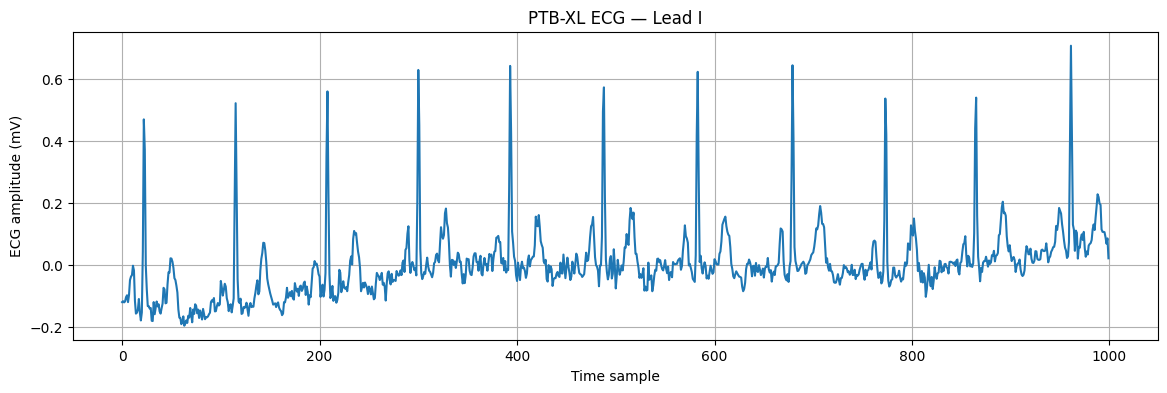

In [4]:
plt.figure(figsize=(14, 4))
plt.plot(signal[:, 0])
plt.title("PTB-XL ECG — Lead I")
plt.xlabel("Time sample")
plt.ylabel("ECG amplitude (mV)")
plt.grid(True)
plt.show()

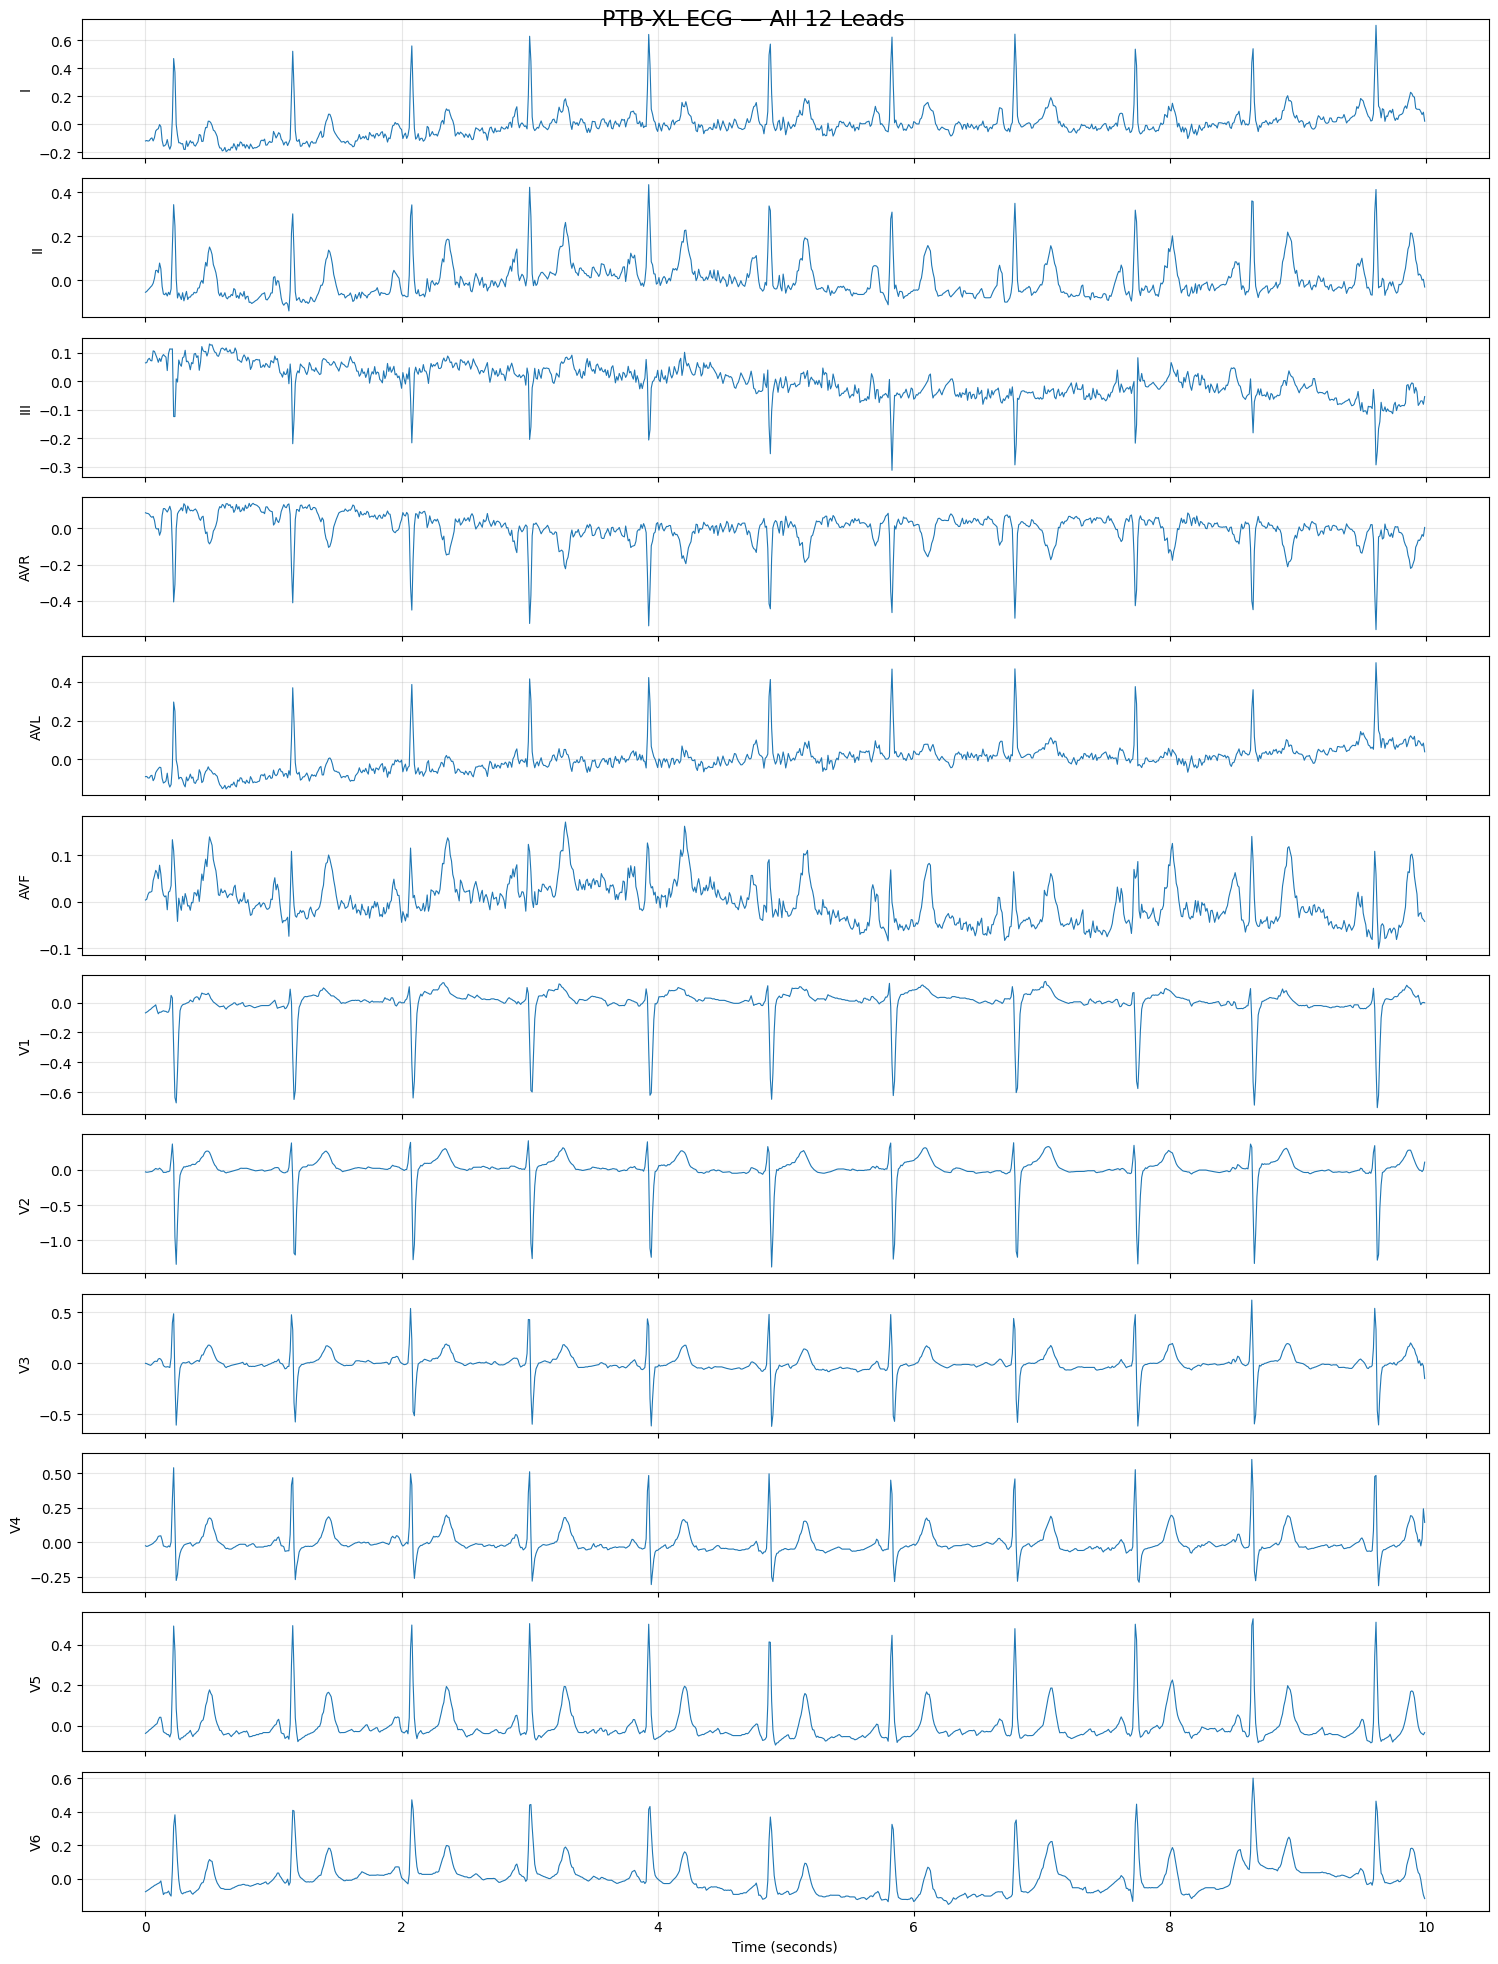

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Time axis in seconds
time = np.arange(signal.shape[0]) / record.fs

# Plot all 12 ECG leads
fig, axes = plt.subplots(12, 1, figsize=(15, 20), sharex=True)

for i, ax in enumerate(axes):
    ax.plot(time, signal[:, i], linewidth=0.8)
    ax.set_ylabel(record.sig_name[i])
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (seconds)")
fig.suptitle("PTB-XL ECG — All 12 Leads", fontsize=16)
plt.tight_layout()
plt.show()

In [6]:
import ast
import pandas as pd

base_url = "https://physionet.org/files/ptb-xl/1.0.3/"

# Get the metadata for ECG ID 1
row = metadata.loc[metadata["ecg_id"] == 1].iloc[0]

# Convert diagnostic codes from text into a Python dictionary
codes = ast.literal_eval(row["scp_codes"]) if isinstance(
    row["scp_codes"], str
) else row["scp_codes"]

# Load the diagnostic-code descriptions
scp = pd.read_csv(base_url + "scp_statements.csv", index_col=0)

columns = [
    c for c in [
        "description",
        "diagnostic",
        "diagnostic_class",
        "diagnostic_subclass",
        "form",
        "rhythm"
    ]
    if c in scp.columns
]

print("ECG ID:", row["ecg_id"])
print("\nRaw dataset codes:")
print(codes)

print("\nMeaning of each code:")
display(scp.loc[scp.index.intersection(codes.keys()), columns])

ECG ID: 1

Raw dataset codes:
{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}

Meaning of each code:


,description,diagnostic,diagnostic_class,diagnostic_subclass,form,rhythm
NORM,normal ECG,1.0,NORM,NORM,NaN,NaN
LVOLT,low QRS voltages in the frontal and horizontal...,NaN,NaN,NaN,1.0,NaN
SR,sinus rhythm,NaN,NaN,NaN,NaN,1.0


In [7]:
import ast
import pandas as pd

# Identify codes that PTB-XL marks as diagnostic
diagnostic_rows = scp[
    pd.to_numeric(scp["diagnostic"], errors="coerce") == 1
]

# Map individual diagnostic codes to their superclass
code_to_class = (
    diagnostic_rows["diagnostic_class"]
    .dropna()
    .to_dict()
)

def parse_codes(value):
    if isinstance(value, dict):
        return value
    if pd.isna(value):
        return {}
    return ast.literal_eval(value)

def get_diagnostic_classes(value):
    codes = parse_codes(value)
    classes = set()

    for code, likelihood in codes.items():
        # Ignore codes with zero likelihood
        if code in code_to_class and float(likelihood) > 0:
            classes.add(code_to_class[code])

    return sorted(classes)

# Create our diagnostic targets
metadata["diagnostic_classes"] = (
    metadata["scp_codes"].apply(get_diagnostic_classes)
)

# Display the number of records per superclass
all_classes = ["NORM", "MI", "STTC", "CD", "HYP"]

counts = pd.DataFrame({
    "Diagnostic class": all_classes,
    "Number of recordings": [
        metadata["diagnostic_classes"].apply(
            lambda labels: cls in labels
        ).sum()
        for cls in all_classes
    ]
})

counts["Percentage of recordings"] = (
    counts["Number of recordings"] / len(metadata) * 100
).round(2)

print("Total ECG recordings:", len(metadata))
print(
    "Records with at least one diagnostic label:",
    metadata["diagnostic_classes"].apply(bool).sum()
)

display(counts)

# Inspect some examples
display(
    metadata[
        ["ecg_id", "patient_id", "scp_codes",
         "diagnostic_classes", "strat_fold"]
    ].head(10)
)

Total ECG recordings: 21799
Records with at least one diagnostic label: 21375


,Diagnostic class,Number of recordings,Percentage of recordings
0,NORM,9514,43.64
1,MI,5469,25.09
2,STTC,5108,23.43
3,CD,4898,22.47
4,HYP,2649,12.15


,ecg_id,patient_id,scp_codes,diagnostic_classes,strat_fold
0,1,15709.0,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",[NORM],3
1,2,13243.0,"{'NORM': 80.0, 'SBRAD': 0.0}",[NORM],2
2,3,20372.0,"{'NORM': 100.0, 'SR': 0.0}",[NORM],5
3,4,17014.0,"{'NORM': 100.0, 'SR': 0.0}",[NORM],3
4,5,17448.0,"{'NORM': 100.0, 'SR': 0.0}",[NORM],4
5,6,19005.0,"{'NORM': 100.0, 'SR': 0.0}",[NORM],4
6,7,16193.0,"{'NORM': 100.0, 'SR': 0.0}",[NORM],7
7,8,11275.0,"{'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}",[MI],9
8,9,18792.0,"{'NORM': 100.0, 'SR': 0.0}",[NORM],10
9,10,9456.0,"{'NORM': 100.0, 'SR': 0.0}",[NORM],9


In [8]:
# Corrected PTB-XL diagnostic superclass mapping
# Do not filter diagnostic codes by their likelihood value here.

def get_diagnostic_classes(value):
    codes = parse_codes(value)

    classes = {
        code_to_class[code]
        for code in codes.keys()
        if code in code_to_class
    }

    return sorted(classes)


metadata["diagnostic_classes"] = (
    metadata["scp_codes"].apply(get_diagnostic_classes)
)

all_classes = ["NORM", "MI", "STTC", "CD", "HYP"]

for cls in all_classes:
    count = metadata["diagnostic_classes"].apply(
        lambda labels: cls in labels
    ).sum()

    percentage = count / len(metadata) * 100

    print(f"{cls:5s}: {count:5d} recordings ({percentage:.2f}%)")

print("\nTotal records:", len(metadata))
print(
    "Records with at least one diagnostic superclass:",
    metadata["diagnostic_classes"].apply(bool).sum()
)

NORM :  9514 recordings (43.64%)
MI   :  5469 recordings (25.09%)
STTC :  5235 recordings (24.01%)
CD   :  4898 recordings (22.47%)
HYP  :  2649 recordings (12.15%)

Total records: 21799
Records with at least one diagnostic superclass: 21388


In [9]:
import pandas as pd

# Five diagnostic superclasses
classes = ["NORM", "MI", "STTC", "CD", "HYP"]

# Create one binary target column for each class
for cls in classes:
    metadata[f"y_{cls}"] = metadata["diagnostic_classes"].apply(
        lambda labels: int(cls in labels)
    )

# Ensure the fold numbers are numeric
metadata["strat_fold"] = pd.to_numeric(
    metadata["strat_fold"], errors="coerce"
)

# Create patient-separated splits using official PTB-XL folds
train_df = metadata[metadata["strat_fold"].between(1, 8)].copy()
val_df = metadata[metadata["strat_fold"] == 9].copy()
test_df = metadata[metadata["strat_fold"] == 10].copy()

# Verify that patients do not overlap across splits
train_patients = set(train_df["patient_id"].dropna())
val_patients = set(val_df["patient_id"].dropna())
test_patients = set(test_df["patient_id"].dropna())

assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)

print("TRAIN:", len(train_df), "recordings")
print("VALIDATION:", len(val_df), "recordings")
print("TEST:", len(test_df), "recordings")

print("\nPatient leakage check: PASSED")

# Display the number of positive labels in each split
target_cols = [f"y_{cls}" for cls in classes]

print("\nTraining label counts:")
print(train_df[target_cols].sum())

print("\nValidation label counts:")
print(val_df[target_cols].sum())

print("\nTest label counts:")
print(test_df[target_cols].sum())

# Save metadata and labels only; no waveform download
train_df.to_csv("/content/ptbxl_train.csv", index=False)
val_df.to_csv("/content/ptbxl_validation.csv", index=False)
test_df.to_csv("/content/ptbxl_test.csv", index=False)

print("\nSaved all three split files in /content/")

TRAIN: 17418 recordings
VALIDATION: 2183 recordings
TEST: 2198 recordings

Patient leakage check: PASSED

Training label counts:
y_NORM    7596
y_MI      4379
y_STTC    4186
y_CD      3907
y_HYP     2119
dtype: int64

Validation label counts:
y_NORM    955
y_MI      540
y_STTC    528
y_CD      495
y_HYP     268
dtype: int64

Test label counts:
y_NORM    963
y_MI      550
y_STTC    521
y_CD      496
y_HYP     262
dtype: int64

Saved all three split files in /content/


In [10]:
import os
import numpy as np
import wfdb
from concurrent.futures import ThreadPoolExecutor, as_completed

TARGET_COLS = ["y_NORM", "y_MI", "y_STTC", "y_CD", "y_HYP"]
MAX_WORKERS = 4

def load_one_record(row):
    path = row["filename_lr"]
    folder, record_name = os.path.split(path)

    record = wfdb.rdrecord(
        record_name,
        pn_dir=f"ptb-xl/1.0.3/{folder}"
    )

    # Convert (time, leads) into (leads, time)
    signal = record.p_signal.astype(np.float32).T

    if signal.shape != (12, 1000):
        raise ValueError(
            f"Unexpected ECG shape {signal.shape} "
            f"for ECG ID {row['ecg_id']}"
        )

    labels = row[TARGET_COLS].to_numpy(dtype=np.float32)

    return int(row["ecg_id"]), signal, labels


def load_subset(df, size, split_name):
    selected = df.sample(
        n=min(size, len(df)),
        random_state=42
    )

    results = []
    errors = []

    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
        futures = {
            executor.submit(load_one_record, row): int(row["ecg_id"])
            for _, row in selected.iterrows()
        }

        for i, future in enumerate(as_completed(futures), start=1):
            try:
                results.append(future.result())
            except Exception as exc:
                errors.append((futures[future], str(exc)))

            if i % 32 == 0 or i == len(futures):
                print(f"{split_name}: processed {i}/{len(futures)}")

    if not results:
        raise RuntimeError(
            f"No ECG recordings loaded for {split_name}. "
            "Check the PhysioNet connection."
        )

    results.sort(key=lambda item: item[0])

    X = np.stack([item[1] for item in results])
    Y = np.stack([item[2] for item in results])

    print(f"\n{split_name}: X={X.shape}, Y={Y.shape}")
    print("Failed records:", len(errors))

    if errors:
        print("First errors:", errors[:3])

    return X, Y


X_train, y_train = load_subset(train_df, 128, "Training")
X_val, y_val = load_subset(val_df, 32, "Validation")
X_test, y_test = load_subset(test_df, 32, "Testing")

print("\nAll subsets loaded.")
print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)

Training: processed 32/128
Training: processed 64/128
Training: processed 96/128
Training: processed 128/128

Training: X=(128, 12, 1000), Y=(128, 5)
Failed records: 0
Validation: processed 32/32

Validation: X=(32, 12, 1000), Y=(32, 5)
Failed records: 0
Testing: processed 32/32

Testing: X=(32, 12, 1000), Y=(32, 5)
Failed records: 0

All subsets loaded.
Training labels: (128, 5)
Validation labels: (32, 5)
Testing labels: (32, 5)


## 3. Read and inspect the metadata

`ptbxl_database.csv` has one row per ECG. The waveform path is in `filename_lr`; labels are recorded in `scp_codes`.

In [ ]:
metadata_path = DATA_DIR / 'ptbxl_database.csv'
scp_path = DATA_DIR / 'scp_statements.csv'
meta = pd.read_csv(metadata_path, index_col='ecg_id')
scp = pd.read_csv(scp_path, index_col=0)

print('Metadata shape:', meta.shape)
print('Unique patients:', meta['patient_id'].nunique())
print('Available columns:')
print(meta.columns.tolist())
display(meta.head())

## 4. Inspect one ECG record

For record ID 1, we'll display its metadata and read the associated waveform. PTB-XL provides 100 Hz signals, so a 10-second recording should have 1,000 time samples on each of its 12 leads.

In [ ]:
ECG_ID = 1
row = meta.loc[ECG_ID]
record_path = DATA_DIR / row['filename_lr']
record = wfdb.rdrecord(str(record_path))
signal = record.p_signal  # shape: (time samples, leads)

print('ECG ID:', ECG_ID)
print('Patient ID:', row['patient_id'])
print('Age:', row.get('age', 'not available'))
print('Sex:', row.get('sex', 'not available'))
print('Record path:', row['filename_lr'])
print('Sampling frequency:', record.fs, 'Hz')
print('Signal shape (samples, leads):', signal.shape)
print('Lead names:', record.sig_name)

assert signal.shape[1] == 12, f'Expected 12 leads, got {signal.shape[1]}'
assert signal.shape[0] == 1000, f'Expected 1000 samples at 100 Hz for 10 sec, got {signal.shape[0]}'
print('Sample record shape check: PASS')

In [ ]:
time_seconds = np.arange(signal.shape[0]) / record.fs
fig, axes = plt.subplots(12, 1, figsize=(14, 18), sharex=True)
for lead_idx, ax in enumerate(axes):
    ax.plot(time_seconds, signal[:, lead_idx], linewidth=0.7)
    ax.set_ylabel(record.sig_name[lead_idx], rotation=0, labelpad=24, va='center')
    ax.grid(True, alpha=0.25)
axes[-1].set_xlabel('Time (seconds)')
fig.suptitle(f'PTB-XL ECG ID {ECG_ID} — 12 leads (100 Hz)', y=1.002)
plt.tight_layout()
plt.show()

## 5. Read the diagnostic annotations

The diagnostic labels are metadata, not inputs to the model during prediction. This cell decodes the SCP codes for the sample and looks up their descriptions when available.

In [ ]:
raw_codes = row['scp_codes']
scp_codes = ast.literal_eval(raw_codes) if isinstance(raw_codes, str) else {}
print('SCP diagnostic codes:', scp_codes)

label_rows = []
for code, likelihood in scp_codes.items():
    description = scp.loc[code, 'description'] if code in scp.index and 'description' in scp.columns else 'Description not found'
    diagnostic = scp.loc[code, 'diagnostic'] if code in scp.index and 'diagnostic' in scp.columns else None
    diagnostic_class = scp.loc[code, 'diagnostic_class'] if code in scp.index and 'diagnostic_class' in scp.columns else None
    label_rows.append({
        'code': code,
        'description': description,
        'likelihood': likelihood,
        'diagnostic': diagnostic,
        'diagnostic_class': diagnostic_class,
    })
display(pd.DataFrame(label_rows))

## 6. Check the official patient-safe folds

PTB-XL provides `strat_fold`. The usual benchmark split uses folds 1–8 for training, fold 9 for validation, and fold 10 for testing. We'll check that patient IDs do not overlap across these partitions.

In [ ]:
if 'strat_fold' not in meta.columns:
    raise KeyError('Expected strat_fold column in PTB-XL metadata')

train_meta = meta[meta['strat_fold'].between(1, 8)]
val_meta = meta[meta['strat_fold'] == 9]
test_meta = meta[meta['strat_fold'] == 10]

train_patients = set(train_meta['patient_id'])
val_patients = set(val_meta['patient_id'])
test_patients = set(test_meta['patient_id'])

print(f'Train: {len(train_meta):,} records, {len(train_patients):,} patients')
print(f'Validation: {len(val_meta):,} records, {len(val_patients):,} patients')
print(f'Test: {len(test_meta):,} records, {len(test_patients):,} patients')
print('Train/validation patient overlap:', len(train_patients & val_patients))
print('Train/test patient overlap:', len(train_patients & test_patients))
print('Validation/test patient overlap:', len(val_patients & test_patients))
assert not (train_patients & val_patients or train_patients & test_patients or val_patients & test_patients)
print('Patient-wise split check: PASS')

## 7. Optional next step: download all 100 Hz waveform files

**Do not run this until the sample-record cells above work.** This downloads the full `records100` waveform collection, which takes time and storage. Metadata and sample files already downloaded above can be reused. Colab's `/content` storage is temporary and is cleared when the runtime is reset.

The command downloads only `records100` rather than the larger 500 Hz data too.

In [ ]:
# OPTIONAL — uncomment and run when ready to train on the full dataset.
# This can take a while and downloads roughly gigabyte-scale data.
# !wget -r -N -c -np -nH --cut-dirs=3 -R 'index.html*' -P /content/ptbxl_data https://physionet.org/files/ptb-xl/1.0.3/records100/

# After download, confirm that this file exists:
# assert (DATA_DIR / 'records100/00000/00001_lr.dat').exists()
# print('100 Hz records folder:', DATA_DIR / 'records100')

## What we have completed

- Connected to the official PTB-XL source.
- Downloaded metadata and one sample waveform.
- Loaded and plotted a 12-lead ECG.
- Inspected its label annotations.
- Verified the official patient-wise fold separation from metadata.

**Next stage:** choose the exact classification target (recommended starting point: the five PTB-XL diagnostic superclasses as a multi-label task), build a baseline, then compare FFN/1D CNN/RNN-family models. These results have not been trained or evaluated in this notebook yet.